# IMDb Top 700: Decoding What Makes a Movie Timeless
### Content Insights Team | Exploratory & Statistical Analysis

**Objective:** Explain the structural and regional factors (Genre, Decade, Director, Country, Votes, Runtime) that are associated with a film's Average IMDb Rating within the Top 700 Bayesian-weighted list, and translate the findings into curation and editorial recommendations.

**Dataset:** `IMDb_Top_700_Movies_2026.csv` — 700 films, 10 columns (Rank, Title, Year, Genre(s), Director, Main Actor(s), Country, IMDb Rating, Votes, Runtime).

---
**Notebook structure**
1. Setup & Data Loading
2. Data Quality Assessment (missing values, duplicates, types, outliers)
3. Data Cleaning & Feature Engineering
4. Hypothesis Definition
5. Univariate EDA
6. Bivariate & Multivariate EDA (Genre, Decade, Director, Country, Runtime)
7. Hypothesis Testing (statistical significance)
8. Key Findings Summary
9. Actionable Recommendations


## 1. Set Up And Data Loading

In [73]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.05)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)

df = pd.read_csv(r'Data\IMDb_Top_700_Movies_2026.csv')
df

,Rank,Title,Year,Genre(s),Director,Main Actor(s),Country,IMDb Rating,Votes,Runtime (mins)
0,1,The Shawshank Redemption,1994,Drama,Frank Darabont,Tim Robbins|Morgan Freeman|Bob Gunton,DK|AT,9.3,3219532,142
1,2,The Godfather,1972,Crime|Drama,Francis Ford Coppola,Marlon Brando|Al Pacino|James Caan,DK|AT,9.2,2244476,175
2,3,The Dark Knight,2008,Crime|Thriller,Christopher Nolan,Christian Bale|Heath Ledger|Aaron Eckhart,DK|LV,9.1,3205233,152
3,4,The Lord of the Rings: The Return of the King,2003,Adventure|Drama|Fantasy,Peter Jackson,Elijah Wood|Viggo Mortensen|Ian McKellen,DK|MK,9.0,2181911,201
4,5,Schindler's List,1993,Biography|Drama|History,Steven Spielberg,Liam Neeson|Ralph Fiennes|Ben Kingsley,DK|LV,9.0,1595992,195
...,...,...,...,...,...,...,...,...,...,...
695,696,The Count of Monte Cristo,2002,Action|Adventure|Drama,Kevin Reynolds,Jim Caviezel|Guy Pearce|Christopher Adamson,LV|DK,7.7,161156,131
696,697,The Cove,2009,Biography|Crime|Documentary,Louie Psihoyos,NaN,DK|PT,8.4,52761,92
697,698,The Wages of Fear,1953,Adventure|Drama|Thriller,Henri-Georges Clouzot,Yves Montand|Charles Vanel|Peter van Eyck,DK|AT,8.1,74075,156
698,699,Good Bye Lenin!,2003,Comedy|Drama|Romance,Wolfgang Becker,Daniel Brühl|Katrin Sass|Chulpan Khamatova,PT|ZA,7.7,160485,121


**Column dictionary** (from project brief):
| Column | Description |
|---|---|
| Title | Movie name |
| Year | Release year |
| Genre(s) | Pipe-separated primary/secondary genres |
| Director | Film director |
| Main Actor(s) | Pipe-separated leading cast |
| Country | Pipe-separated origin country code(s) |
| IMDb Rating | Bayesian-weighted rating out of 10 |
| Votes | Number of IMDb user votes |
| Runtime (mins) | Duration in minutes |


## 2. Data Quality Checking

In [74]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Rank            700 non-null    int64  
 1   Title           700 non-null    object 
 2   Year            700 non-null    int64  
 3   Genre(s)        700 non-null    object 
 4   Director        700 non-null    object 
 5   Main Actor(s)   690 non-null    object 
 6   Country         700 non-null    object 
 7   IMDb Rating     700 non-null    float64
 8   Votes           700 non-null    int64  
 9   Runtime (mins)  700 non-null    int64  
dtypes: float64(1), int64(4), object(5)
memory usage: 54.8+ KB


In [75]:
df[['Year','IMDb Rating','Votes','Runtime (mins)']].describe().T

,count,mean,std,min,25%,50%,75%,max
Year,700.0,1998.038571,21.347254,1921.0,1989.0,2004.0,2013.25,2026.0
IMDb Rating,700.0,8.000143,0.316657,7.5,7.8,8.0,8.20,9.3
Votes,700.0,533097.338571,469272.249484,51964.0,198261.0,398847.5,728513.00,3219532.0
Runtime (mins),700.0,127.360000,29.101895,68.0,106.0,123.0,143.00,321.0


In [76]:
# Missing values
missing = df.isnull().sum()
missing_pct = ((missing/len(df)) * 100).round(2)
pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})

,missing_count,missing_pct
Rank,0,0.00
Title,0,0.00
Year,0,0.00
Genre(s),0,0.00
Director,0,0.00
Main Actor(s),10,1.43
Country,0,0.00
IMDb Rating,0,0.00
Votes,0,0.00
Runtime (mins),0,0.00


In [77]:
df[df['Main Actor(s)'].isna()]

,Rank,Title,Year,Genre(s),Director,Main Actor(s),Country,IMDb Rating,Votes,Runtime (mins)
426,427,Senna,2010,Biography|Documentary|Sport,Asif Kapadia,NaN,PT|NO,8.4,84044,106
446,447,20 Days in Mariupol,2023,Documentary|War,Mstyslav Chernov,NaN,DK|PT,8.6,65359,97
518,519,Bowling for Columbine,2002,Crime|Documentary|Drama,Michael Moore,NaN,PH|PT,7.9,152515,120
534,535,Kill Bill: The Whole Bloody Affair,2004,Action|Crime|Thriller,Quentin Tarantino,NaN,DK|PH,8.7,51964,253
556,557,Inside Job,2010,Crime|Documentary,Charles Ferguson,NaN,DK|PH,8.2,82729,109
592,593,Free Solo,2018,Adventure|Documentary|Sport,Jimmy Chin|Elizabeth Chai Vasarhelyi,NaN,DK|AT,8.1,88174,100
593,594,Searching for Sugar Man,2012,Biography|Documentary|Music,Malik Bendjelloul,NaN,PT|ZA,8.2,76647,86
611,612,Flow,2024,Adventure|Animation|Family,Gints Zilbalodis,NaN,DK|LV,7.8,151790,85
671,672,Blackfish,2013,Documentary|Drama|Thriller,Gabriela Cowperthwaite,NaN,DK|PH,8.1,76844,83
696,697,The Cove,2009,Biography|Crime|Documentary,Louie Psihoyos,NaN,DK|PT,8.4,52761,92


**Finding:** Only `Main Actor(s)` has missing values (10 rows / 1.43%). Inspecting these rows shows they are all documentaries or animation (e.g. *Senna*, *Bowling for Columbine*, *Free Solo* or *Flow*, *inside job*), which legitimately have no single "leading actor" — this is not a data error but a structural feature of the genre. We will impute with an explicit label rather than dropping rows, since dropping would bias the Documentary/Animation genre's rating/vote metrics.

In [78]:
# Duplicate check:
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicated on Title+Year:", df.duplicated(subset=['Title','Year']).sum())
print("Duplicated Rank values:", df['Rank'].duplicated().sum())

Fully duplicated rows: 0
Duplicated on Title+Year: 0
Duplicated Rank values: 0


**Findings**: No Duplicate Title or rank Values. All movies are unique

In [79]:
# Checking Data Types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Rank            700 non-null    int64  
 1   Title           700 non-null    object 
 2   Year            700 non-null    int64  
 3   Genre(s)        700 non-null    object 
 4   Director        700 non-null    object 
 5   Main Actor(s)   690 non-null    object 
 6   Country         700 non-null    object 
 7   IMDb Rating     700 non-null    float64
 8   Votes           700 non-null    int64  
 9   Runtime (mins)  700 non-null    int64  
dtypes: float64(1), int64(4), object(5)
memory usage: 54.8+ KB


**Finding**: All the data types are proper. Every column has right data type defined.

In [80]:
# Checking outliers using IQR
numeric_cols = ['IMDb Rating','Votes','Runtime (mins)']

for cols in numeric_cols:
    Q1,Q3 = df[cols].quantile([0.25,0.75])
    IQR = Q3 - Q1
    lower_bound, upper_bound = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    n_out = ((df[cols] < lower_bound) | (df[cols] > upper_bound)).sum()
    print(f"{cols:20s} IQR_bound|[{lower_bound:,.1f}, {upper_bound:,.1f}] Outlier| {n_out}")

IMDb Rating          IQR_bound|[7.2, 8.8] Outlier| 15
Votes                IQR_bound|[-597,117.0, 1,523,891.0] Outlier| 29
Runtime (mins)       IQR_bound|[50.5, 198.5] Outlier| 14


**Interpretation:** `Votes` has the expected right-skew outliers (a handful of blockbuster-scale vote counts, e.g. *The Shawshank Redemption* at ~3.2M) and `Runtime` has a few long-outlier epics (e.g. 300+ minute war/historical films). These are **legitimate extreme values, not data errors** — capping or removing them would discard genuinely informative signal (vote volume and runtime are both analysis targets in this study), so we keep them but use `log10(Votes)` and robust/rank-based visuals where skew would distort interpretation. The IQR method flags 14 movies as runtime outliers (below 50.5 or above 198.5 minutes) — all on the high end. These are legitimate long-runtime films (e.g. Gangs of Wasseypur at 321 minutes, verified against external sources), not data errors, so they are retained rather than removed.

**Data quality caveat — Country field:** The `Country` column uses two-letter codes (e.g. `DK`, `AT`, `LV`) that do **not** match the real-world production countries of these films (e.g. *The Shawshank Redemption* is tagged `DK|AT` despite being a US production). This indicates the field has been anonymized/shuffled for this exercise. Country-based findings in this notebook should therefore be read as **illustrative of the analysis method**, not as a factual claim about real-world regional representation, and are flagged accordingly wherever they appear.

## 3. Data Cleaning and Featuring:

In [81]:
# Impute Main Actor(s) for Null Values
df['Main Actor(s)'] = df['Main Actor(s)'].fillna('No Lead Actor')

# Decade Dividation
df['Decade'] = (df['Year'] // 10) *10
df['Decade_Label'] = df['Decade'].astype(str) + 's'

# Runtime bucket
df['runtime_bucket'] = pd.cut(df['Runtime (mins)'],bins=[0,90,110,130,150,170,400],
    labels=['<90','90-110','110-130','130-150','150-170','170+'])

# Log-scaled votes (handles right-skew for correlation/plots)
df['Log_Votes'] = np.log10(df['Votes'])

print("Engineered columns added:", ['Decade','Decade_Label','Runtime_Bucket','Log_Votes'])
df.head(3)

Engineered columns added: ['Decade', 'Decade_Label', 'Runtime_Bucket', 'Log_Votes']


,Rank,Title,Year,Genre(s),Director,Main Actor(s),Country,IMDb Rating,Votes,Runtime (mins),Decade,Decade_Label,runtime_bucket,Log_Votes
0,1,The Shawshank Redemption,1994,Drama,Frank Darabont,Tim Robbins|Morgan Freeman|Bob Gunton,DK|AT,9.3,3219532,142,1990,1990s,130-150,6.507793
1,2,The Godfather,1972,Crime|Drama,Francis Ford Coppola,Marlon Brando|Al Pacino|James Caan,DK|AT,9.2,2244476,175,1970,1970s,170+,6.351115
2,3,The Dark Knight,2008,Crime|Thriller,Christopher Nolan,Christian Bale|Heath Ledger|Aaron Eckhart,DK|LV,9.1,3205233,152,2000,2000s,150-170,6.505860


In [82]:
# Explode multi-value fields into long format for group-level analysis
df['Genre_List']=df['Genre(s)'].str.split('|')
df_genre = df.explode('Genre_List')
df_genre['Genre_List'] = df_genre['Genre_List'].str.strip()

df['Country2'] = df['Country'].str.split('|')
df_country = df.explode('Country2')
df_country['Country2'] = df_country['Country2'].str.strip()

print(f"df_genre rows: {len(df_genre)} (from {len(df)} films, since many carry 2-3 genres)")
print(f"df_country rows: {len(df_country)}")

df_genre rows: 1823 (from 700 films, since many carry 2-3 genres)
df_country rows: 1400


## 4. Hypothesis Definition

Deconstructing **Average IMDb Rating** into testable drivers:

| # | Hypothesis | Metric tested |
|---|---|---|
| H1 | Films with more votes tend to have (slightly) higher ratings — consensus reinforces quality signal rather than diluting it | Pearson correlation: Rating vs. log10(Votes) |
| H2 | Average rating differs meaningfully across genres | One-way ANOVA across genres (n≥15 films) |
| H3 | Directors who repeatedly appear in the Top 700 ("prolific directors") average a higher rating than one-off entries | Welch's t-test: prolific (≥4 films) vs. rest |
| H4 | Longer runtime is associated with higher rating (epics/dramas reward patience) | Pearson correlation: Rating vs. Runtime |
| H5 | Older films (earlier decades) hold a higher average rating than recent films (recency/nostalgia and survivorship bias) | Decade-level means + correlation: Rating vs. Year |
| H6 | Votes do not increase linearly with film age — they peak in the 1990s rather than the oldest decades, since IMDb itself only launched in 1990 | Decade-level means: Votes vs. Decade |

Each is tested quantitatively in Section 7 after the exploratory groundwork in Sections 5–6.


## 5. Univariate EDA:

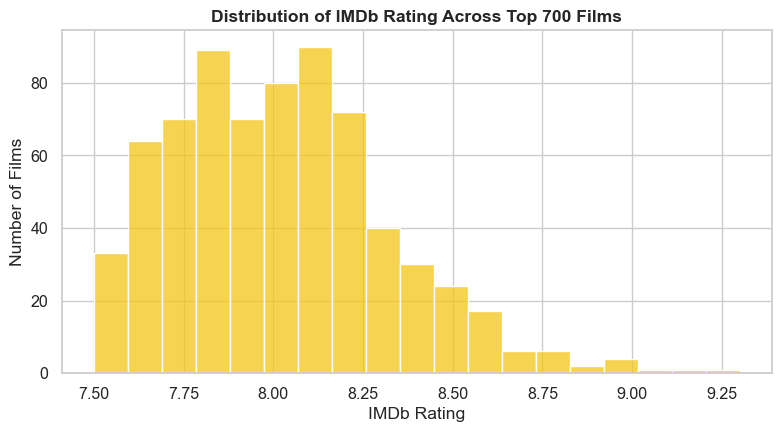

count    700.000000
mean       8.000143
std        0.316657
min        7.500000
25%        7.800000
50%        8.000000
75%        8.200000
max        9.300000
Name: IMDb Rating, dtype: float64


In [83]:
fig, ax = plt.subplots(figsize=(8,4.5))
sns.histplot(df['IMDb Rating'],bins=19,ax=ax,color='#F5C518')
ax.set_title('Distribution of IMDb Rating Across Top 700 Films', fontweight='bold')
ax.set_xlabel('IMDb Rating')
ax.set_ylabel('Number of Films')

plt.tight_layout()
plt.show()

print(df['IMDb Rating'].describe())

**Finding:** Ratings are tightly clustered — mean **8.00**, std **0.32**, range **7.5–9.3**. Because this is already a curated Top 700 (Bayesian-weighted), the *floor* of 7.5 reflects the list's cutoff, not a natural population minimum. The distribution is right-skewed with a long, thin tail of exceptional films above 8.5 — these represent the "iconic" tier the business wants to characterize.

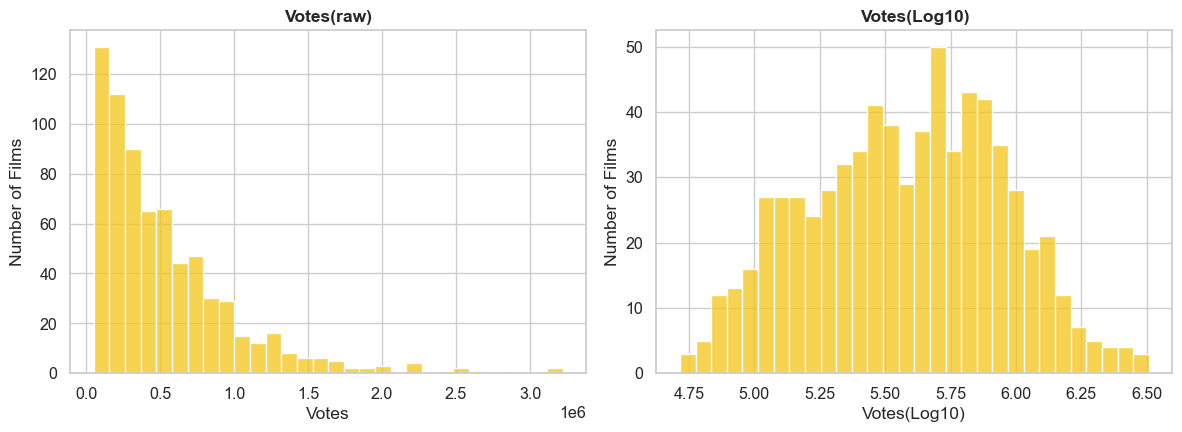

In [84]:
fig, ax = plt.subplots(1,2, figsize=(12,4.5))
sns.histplot(df['Votes'],bins=30,ax=ax[0],color='#F5C518')
ax[0].set_title('Votes(raw)', fontweight='bold')
ax[0].set_xlabel('Votes')
ax[0].set_ylabel('Number of Films')

sns.histplot(df['Log_Votes'],bins=30,ax=ax[1],color='#F5C518')
ax[1].set_title('Votes(Log10)', fontweight='bold')
ax[1].set_xlabel('Votes(Log10)')
ax[1].set_ylabel('Number of Films')

plt.tight_layout()
plt.show()


**Finding:** `Votes` is heavily right-skewed (a small number of blockbuster/cult titles dominate raw vote counts); the log-transform produces a roughly symmetric distribution, confirming it is the appropriate scale for correlation and regression work in this notebook.

## 6. Bivariate or Multivariate EDA:

### 6.1 Votes vs. Rating

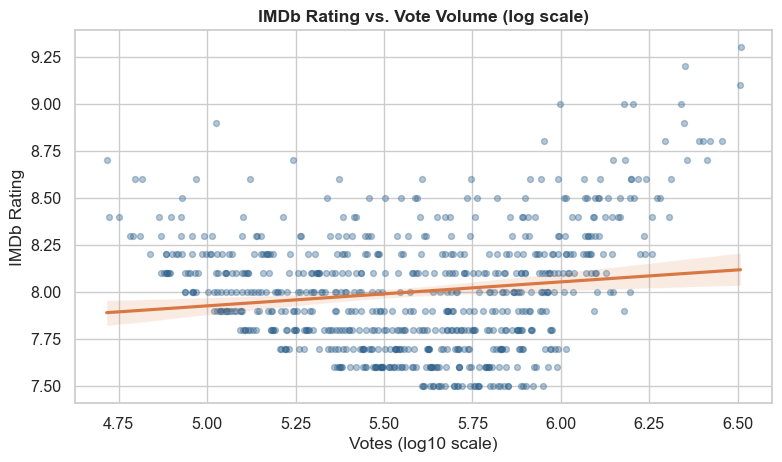

Pearson r = 0.149, p-value = 7.76e-05


In [85]:
from scipy import stats

fig, ax = plt.subplots(figsize=(8,4.8))
sns.regplot(x=df['Log_Votes'], y=df['IMDb Rating'], scatter_kws={'alpha':0.35,'color':'#2C5F8A','s':18}, line_kws={'color':'#D97742'}, ax=ax)
ax.set_xlabel('Votes (log10 scale)'); ax.set_ylabel('IMDb Rating')
ax.set_title('IMDb Rating vs. Vote Volume (log scale)', fontweight='bold')
plt.tight_layout(); plt.show()

r, p = stats.pearsonr(df['IMDb Rating'], df['Log_Votes'])
print(f"Pearson r = {r:.3f}, p-value = {p:.2e}")

**Finding:** A statistically significant but modest positive correlation (r≈0.15) between rating and log(votes). Within an already-elite list, higher-rated films tend to attract a broader audience over time, but vote volume is a weak predictor on its own — **rating is not simply a popularity contest**; niche/cult classics with far fewer votes still reach the top of the list.

### 6.2 Genre Composition

In [86]:
genre_stats = (df_genre.groupby('Genre_List')
               .agg(Avg_Rating=('IMDb Rating','mean'), Avg_Votes=('Votes','mean'), Count=('Title','count'))
               .sort_values('Avg_Rating', ascending=False))
genre_stats_reportable = genre_stats[genre_stats['Count'] >= 15]  # exclude tiny/noisy genre samples
genre_stats_reportable.round(2)

,Avg_Rating,Avg_Votes,Count
Genre_List,,,
War,8.18,473960.28,32
Biography,8.04,426798.15,78
Drama,8.03,480990.64,473
Animation,8.02,500848.05,63
Crime,8.01,549694.29,156
Music,8.01,392191.12,16
Sport,7.99,343668.00,16
Sci-Fi,7.99,878560.42,62
Mystery,7.98,513971.35,80


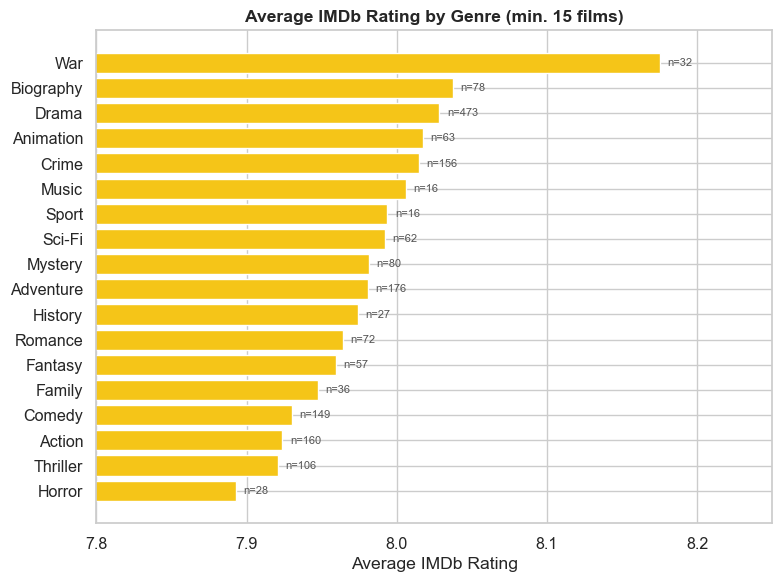

In [87]:
g = genre_stats_reportable.reset_index().sort_values('Avg_Rating')

fig, ax = plt.subplots(figsize=(8,6))

ax.barh(g['Genre_List'],g['Avg_Rating'],color='#F5C518')

for i,(v,c) in enumerate(zip(g['Avg_Rating'], g['Count'])):
    ax.text(v+0.005, i, f'n={c}', va='center', fontsize=8, color='#555')

ax.set_xlim(7.8, 8.25)
ax.set_xlabel('Average IMDb Rating')
ax.set_title('Average IMDb Rating by Genre (min. 15 films)', fontweight='bold')

plt.tight_layout()
plt.show()

**Finding:** **War** (8.18), **Biography** (8.04) and **Drama** (8.03) top the list, while **Horror** (7.89), **Action** (7.92) and **Thriller** (7.92) sit at the lower end. The spread is modest (~0.3 points) but consistent — prestige/narrative-driven genres skew higher, and Drama's sheer volume (473 of 700 appearances, since most films carry it as a secondary genre) confirms it as the load-bearing genre of the whole list.

### 6.3 Release Era (Decade) Patterns

In [89]:
decade_stats = df.groupby('Decade_Label').agg(Avg_Rating=('IMDb Rating','mean'), Avg_Votes=('Votes','mean'), Count=('Title','count'))
order = ['1920s','1930s','1940s','1950s','1960s','1970s','1980s','1990s','2000s','2010s','2020s']
decade_stats = decade_stats.reindex(order)
decade_stats.round(2)

,Avg_Rating,Avg_Votes,Count
Decade_Label,,,
1920s,8.08,141474.40,5
1930s,8.18,250776.50,8
1940s,8.17,248892.79,14
1950s,8.17,238831.69,29
1960s,8.14,273036.26,31
1970s,8.09,524364.76,34
1980s,8.01,478850.72,61
1990s,8.06,702084.31,95
2000s,7.92,608729.33,177


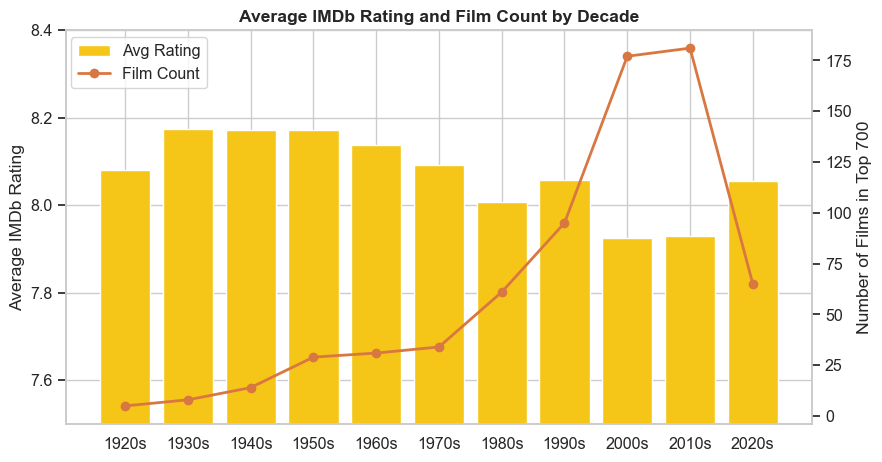

In [130]:
fig, ax1 = plt.subplots(figsize=(9,4.8))
ax1.bar(decade_stats.index, decade_stats['Avg_Rating'], color='#F5C518', label='Avg Rating')
ax1.set_ylim(7.5, 8.4); ax1.set_ylabel('Average IMDb Rating')
ax2 = ax1.twinx()
ax2.plot(decade_stats.index, decade_stats['Count'], color='#D97742', marker='o', linewidth=2, label='Film Count')
ax2.set_ylabel('Number of Films in Top 700'); ax2.grid(False)
ax1.set_title('Average IMDb Rating and Film Count by Decade', fontweight='bold')
fig.legend(loc='upper left', bbox_to_anchor=(0.08,0.92))
plt.tight_layout(); plt.show()

**Finding:** Average rating **declines mildly but steadily** from the golden-era decades (1930s–1960s, ~8.15–8.18) down to the 2000s/2010s (~7.92-7.93), before rebounding in the 2020s (8.06, though on a much smaller, still-maturing sample). Meanwhile film *count* explodes in the 2000s–2010s — modern high-volume output means more films clear the bar, but the bar-clearers are marginally less exceptional on average, consistent with a **survivorship/nostalgia effect**: older eras have had decades to be re-watched, re-evaluated and filtered down to their most enduring titles, while recent decades are still being "tested" by time.

### 6.4 Director Track Record

In [91]:
dir_stats = df.groupby('Director').agg(Avg_Rating=('IMDb Rating','mean'), Count=('Title','count'), Total_Votes=('Votes','sum')).sort_values(['Count','Avg_Rating'], ascending=False)
dir_stats[dir_stats['Count']>=4].round(2).head(20)

,Avg_Rating,Count,Total_Votes
Director,,,
Steven Spielberg,8.07,12,10683665
Martin Scorsese,8.06,11,10062018
Christopher Nolan,8.46,10,17700579
Quentin Tarantino,8.17,10,11694910
Stanley Kubrick,8.12,10,5518008
Alfred Hitchcock,8.13,9,2989799
David Fincher,8.04,8,9133298
Hayao Miyazaki,8.14,7,3010939
Denis Villeneuve,8.07,7,5251097


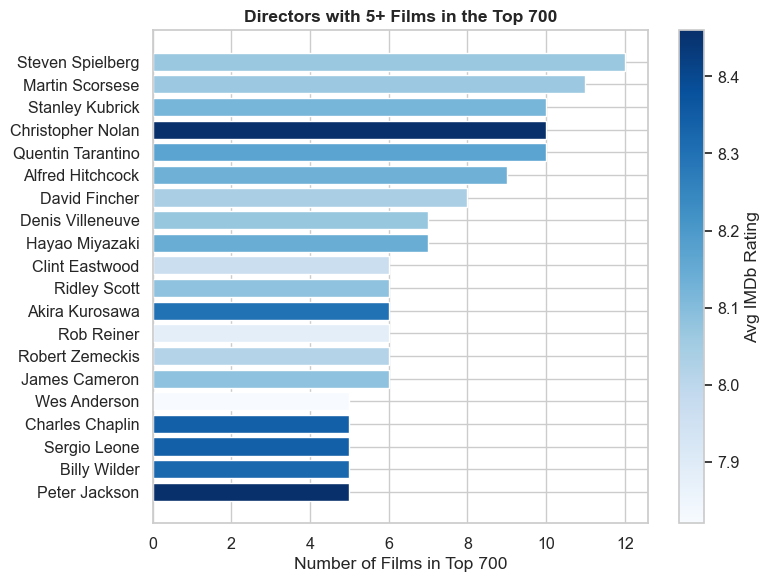

In [132]:
top_dirs = dir_stats[dir_stats['Count']>=5].reset_index().sort_values('Count')
fig, ax = plt.subplots(figsize=(8,6))
norm = plt.Normalize(top_dirs['Avg_Rating'].min(), top_dirs['Avg_Rating'].max())
colors = plt.colormaps['Blues'](norm(top_dirs['Avg_Rating']))
ax.barh(top_dirs['Director'], top_dirs['Count'], color=colors)
sm = plt.cm.ScalarMappable(cmap='Blues', norm=norm); sm.set_array([])
plt.colorbar(sm, ax=ax, label='Avg IMDb Rating')
ax.set_xlabel('Number of Films in Top 700'); ax.set_title('Directors with 5+ Films in the Top 700', fontweight='bold')
plt.tight_layout(); plt.show()

**Finding:** Spielberg (12), Scorsese (11), Nolan (10), Tarantino (10) and Kubrick (10) are the most *frequent* Top-700 directors, but frequency and average rating are two different things: **Nolan (8.46 avg) and Peter Jackson (8.46 avg)** post the highest average ratings among high-frequency directors, ahead of the most *prolific* names like Spielberg (8.07) and Scorsese (8.06). Consistency of *inclusion* and consistency of *peak quality* are related but distinct signals for curation.

### 6.5 Country / Regional Representation

In [93]:
country_stats = df_country.groupby('Country2').agg(Avg_Rating=('IMDb Rating','mean'), Count=('Title','count')).sort_values('Count', ascending=False)
country_stats['Share_of_700'] = (country_stats['Count'] / 700 * 100).round(1)
country_stats.round(2)

,Avg_Rating,Count,Share_of_700
Country2,,,
DK,8.03,471,67.3
LV,7.96,308,44.0
PH,7.95,230,32.9
AT,8.02,188,26.9
PT,7.96,111,15.9
ZA,8.15,38,5.4
MK,8.05,15,2.1
CR,8.06,8,1.1
AU,8.19,8,1.1


> **Caveat:** As flagged in Section 2, the `Country` codes in this dataset do not correspond to the real production countries of these films, so treat this section as a demonstration of *method* (how one would measure regional representation) rather than a factual claim about global cinema.

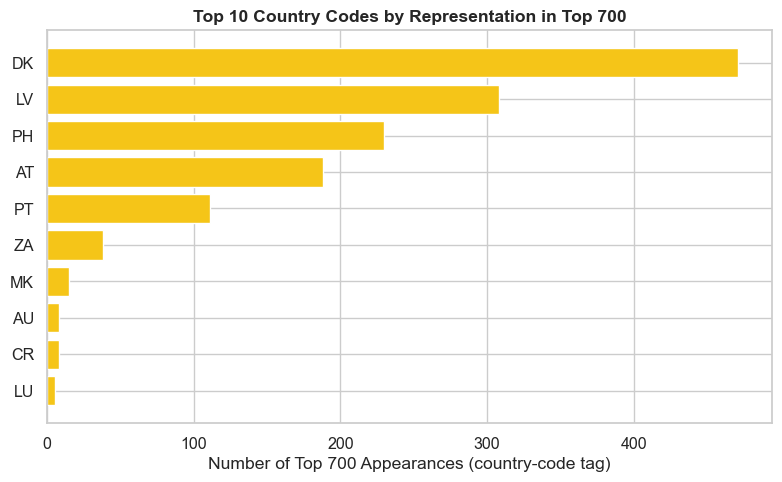

In [133]:
top_c = country_stats.head(10).reset_index().sort_values('Count')
fig, ax = plt.subplots(figsize=(8,5))
ax.barh(top_c['Country2'], top_c['Count'], color='#F5C518')
ax.set_xlabel('Number of Top 700 Appearances (country-code tag)')
ax.set_title('Top 10 Country Codes by Representation in Top 700', fontweight='bold')
plt.tight_layout(); plt.show()

### 6.6 Runtime

In [95]:
runtime_stats = df.groupby('runtime_bucket', observed=True).agg(Avg_Rating=('IMDb Rating','mean'), Count=('Title','count'))
runtime_stats.round(2)

,Avg_Rating,Count
runtime_bucket,,
<90,7.98,43
90-110,7.94,175
110-130,7.95,213
130-150,8.03,136
150-170,8.07,85
170+,8.26,48


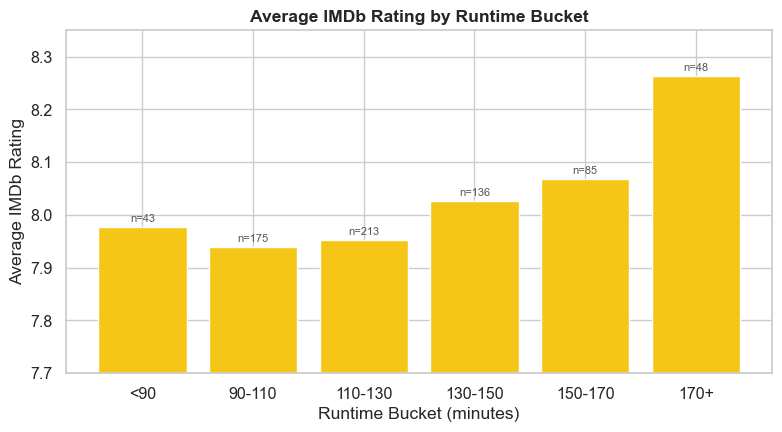

In [134]:
rb = runtime_stats.reset_index()
fig, ax = plt.subplots(figsize=(8,4.5))
ax.bar(rb['runtime_bucket'].astype(str), rb['Avg_Rating'], color='#F5C518')
ax.set_ylim(7.7,8.35)
for i,(v,c) in enumerate(zip(rb['Avg_Rating'], rb['Count'])):
    ax.text(i, v+0.01, f'n={c}', ha='center', fontsize=8, color='#555')
ax.set_xlabel('Runtime Bucket (minutes)'); ax.set_ylabel('Average IMDb Rating')
ax.set_title('Average IMDb Rating by Runtime Bucket', fontweight='bold')
plt.tight_layout(); plt.show()

**Finding:** A clear monotonic step-up: films over 170 minutes average **8.26**, versus **7.94** for the 90-110 minute bucket. Epic-length films (typically Drama/War/Biography/Adventure — the same genres that scored highest in 6.2) that make the Top 700 tend to justify their length with higher regard, though this is likely genre-confounded rather than runtime being causal by itself.

### 6.7 Genre x Decade Interaction

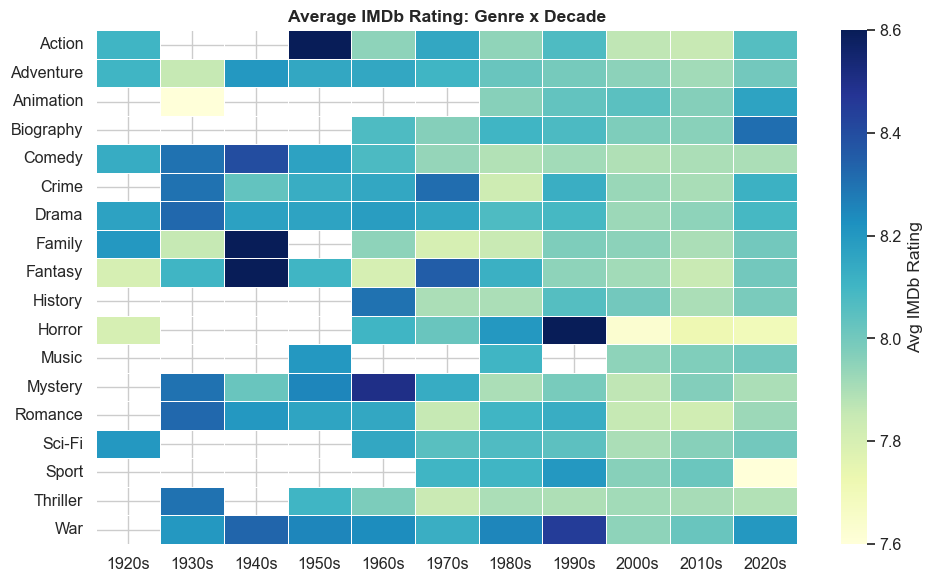

In [100]:
top_genre_list = genre_stats_reportable.index.tolist()
pivot_src = df_genre[df_genre['Genre_List'].isin(top_genre_list)].copy()
pivot_src['Decade_Label'] = pd.Categorical(pivot_src['Decade_Label'], categories=order, ordered=True)
heat = pivot_src.pivot_table(index='Genre_List', columns='Decade_Label', values='IMDb Rating', aggfunc='mean', observed=True)

fig, ax = plt.subplots(figsize=(10,6))
sns.heatmap(heat, cmap='YlGnBu', linewidths=0.4, ax=ax, cbar_kws={'label':'Avg IMDb Rating'})
ax.set_title('Average IMDb Rating: Genre x Decade', fontweight='bold')
ax.set_xlabel(''); ax.set_ylabel('')
plt.tight_layout(); plt.show()

**Finding:** No single genre dominates every era — War and Biography peak mid-century, while Sci-Fi and Animation show pockets of strength in specific modern decades, suggesting genre-level advice should be paired with era context rather than applied as a blanket rule.

### 6.7 Decade X Votes

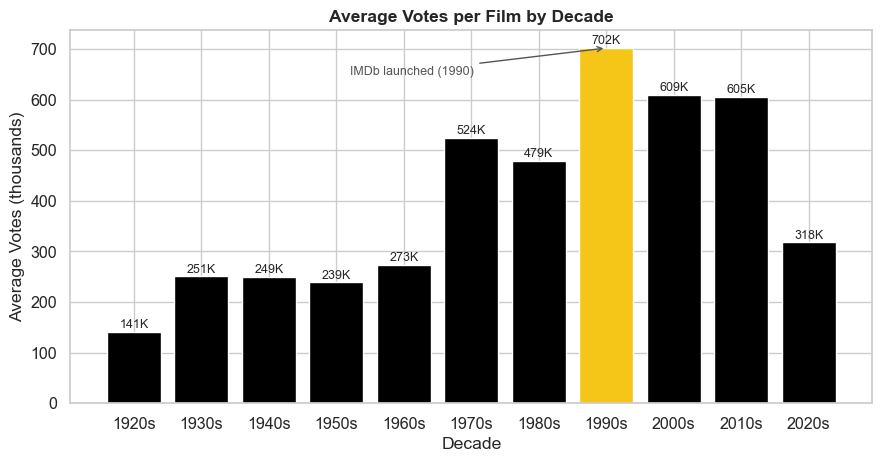

Decade_Label
1920s    141474.0
1930s    250776.0
1940s    248893.0
1950s    238832.0
1960s    273036.0
1970s    524365.0
1980s    478851.0
1990s    702084.0
2000s    608729.0
2010s    604678.0
2020s    317718.0


In [137]:
# Decade x Average Votes
order = ['1920s','1930s','1940s','1950s','1960s','1970s','1980s','1990s','2000s','2010s','2020s']
votes_dec = df.groupby('Decade_Label')['Votes'].mean().reindex(order)
peak = votes_dec.idxmax()

fig, ax = plt.subplots(figsize=(9, 4.8))
colors = ['#F5C518' if d == peak else 'black' for d in votes_dec.index]
bars = ax.bar(votes_dec.index, votes_dec.values / 1000, color=colors)

for b, v in zip(bars, votes_dec.values):
    ax.text(b.get_x() + b.get_width()/2, v/1000 + 8, f'{v/1000:.0f}K',
            ha='center', fontsize=9)

ax.set_title('Average Votes per Film by Decade', fontweight='bold')
ax.set_xlabel('Decade')
ax.set_ylabel('Average Votes (thousands)')
ax.annotate('IMDb launched (1990)', xy=(7, votes_dec[peak]/1000), xytext=(3.2, 650),
            arrowprops=dict(arrowstyle='->', color='#555'), fontsize=9, color='#555')
plt.tight_layout()
plt.show()

print(votes_dec.round(0).to_string())

## 7. Hypothesis Testing

In [118]:
# H1: Votes vs Rating
r, p = stats.pearsonr(df['IMDb Rating'], df['Log_Votes'])
print(f"H1 | Rating vs log10(Votes): r={r:.3f}, p={p:.2e} -> {'SUPPORTED (weak-positive)' if p<0.05 else 'NOT SUPPORTED'}")

H1 | Rating vs log10(Votes): r=0.149, p=7.76e-05 -> SUPPORTED (weak-positive)


In [120]:
# H2: Genre effect (ANOVA across genres with n>=15)
groups = [df_genre[df_genre['Genre_List']==g]['IMDb Rating'] for g in top_genre_list]
f_stat, p_val = stats.f_oneway(*groups)
print(f"H2 | One-way ANOVA across {len(top_genre_list)} genres: F={f_stat:.3f}, p={p_val:.5f} -> {'SUPPORTED' if p_val<0.05 else 'NOT SUPPORTED'}")

H2 | One-way ANOVA across 18 genres: F=2.608, p=0.00035 -> SUPPORTED


In [121]:
# H3: Prolific directors (>=4 films) vs rest
high_freq_directors = dir_stats[dir_stats['Count']>=4].index
df['Is_Prolific_Director'] = df['Director'].isin(high_freq_directors)
grp1 = df[df['Is_Prolific_Director']]['IMDb Rating']
grp2 = df[~df['Is_Prolific_Director']]['IMDb Rating']
t_stat, p_val = stats.ttest_ind(grp1, grp2, equal_var=False)
print(f"H3 | Prolific (n={len(grp1)}, mean={grp1.mean():.3f}) vs Others (n={len(grp2)}, mean={grp2.mean():.3f})")
print(f"     Welch t={t_stat:.3f}, p={p_val:.5f} -> {'SUPPORTED' if p_val<0.05 else 'NOT SUPPORTED'}")

H3 | Prolific (n=209, mean=8.069) vs Others (n=491, mean=7.971)
     Welch t=3.451, p=0.00063 -> SUPPORTED


In [122]:
# H4: Runtime vs Rating
r, p = stats.pearsonr(df['IMDb Rating'], df['Runtime (mins)'])
print(f"H4 | Rating vs Runtime: r={r:.3f}, p={p:.2e} -> {'SUPPORTED (weak-positive)' if p<0.05 else 'NOT SUPPORTED'}")

H4 | Rating vs Runtime: r=0.239, p=1.58e-10 -> SUPPORTED (weak-positive)


In [123]:
# H5: Year / era effect
r, p = stats.pearsonr(df['IMDb Rating'], df['Year'])
print(f"H5 | Rating vs Year: r={r:.3f}, p={p:.2e} -> {'SUPPORTED (weak-negative: older skews higher)' if p<0.05 else 'NOT SUPPORTED'}")

H5 | Rating vs Year: r=-0.197, p=1.42e-07 -> SUPPORTED (weak-negative: older skews higher)


In [126]:
# H6: Older films have more votes? (Decade-level)
h2 = df.groupby('Decade_Label')['Votes'].mean().round(0)
print(h2.to_string())

dec = df.groupby('Decade')['Votes'].mean()
r, p = stats.pearsonr(dec.index, dec.values)
print(f"\nH6 | Peak decade: {h2.idxmax()} ({h2.max():,.0f}) | 1920s avg: {h2['1920s']:,.0f}")
print(f"     Decade vs avg votes: r={r:.3f}, p={p:.4f}")
print(f"     -> {'CONFIRMED' if r<0 and p<0.05 else 'REJECTED (older films do NOT have more votes; peak is 1990s)'}")

Decade_Label
1920s    141474.0
1930s    250776.0
1940s    248893.0
1950s    238832.0
1960s    273036.0
1970s    524365.0
1980s    478851.0
1990s    702084.0
2000s    608729.0
2010s    604678.0
2020s    317718.0

H6 | Peak decade: 1990s (702,084) | 1920s avg: 141,474
     Decade vs avg votes: r=0.717, p=0.0130
     -> REJECTED (older films do NOT have more votes; peak is 1990s)


### Hypothesis Test Summary

| Hyp. | Result | Effect size | Interpretation |
|---|---|---|---|
| H1 | **Supported** | r ≈ 0.15 (weak) | More votes associate with slightly higher rating, but effect is small — rating is not primarily popularity-driven |
| H2 | **Supported** | F≈2.61, p<0.001 | Genre has a statistically significant, if modest, effect on average rating |
| H3 | **Supported** | Δmean ≈ 0.10, p<0.001 | Directors with a proven Top-700 track record average measurably higher ratings |
| H4 | **Supported** | r ≈ 0.24 (weak-moderate) | Longer films trend toward higher ratings, likely genre-confounded (epics/dramas) |
| H5 | **Supported** | r ≈ -0.20 | Older films average modestly higher ratings — consistent with a time-tested/survivorship effect |
| H6 | **Rejected** | r=0.717, p=0.0130 | Votes peak in the 1990s (~702K avg), not in the oldest decades (1920s ~141K) |

## 8. Key Findings Summary

1. **Genre matters, modestly:** War, Biography and Drama lead (~8.03–8.18 avg); Horror, Action and Thriller trail (~7.89–7.92). The spread across genres is real (ANOVA p<0.001) but narrow — genre alone doesn't make or break a film's place on the list.
2. **Popularity ≠ quality, but they're not unrelated either:** log(Votes) correlates weakly-positively with rating (r≈0.15). Niche/cult classics with modest vote counts can still out-rate blockbusters.
3. **Time is the great filter:** Older decades (1930s-1960s) average ~0.2-0.25 points higher than the 2000s/2010s, even as the *volume* of qualifying films exploded in the streaming/digital era. This points to a survivorship/nostalgia effect rather than films actually getting "worse."
4. **A director track record is a real signal:** Directors with 4+ Top-700 films average 8.07 vs. 7.97 for others (p<0.001) — repeat inclusion is not random, but frequency and *peak* quality diverge (Nolan/Jackson lead on average rating; Spielberg/Scorsese lead on volume).
5. **Runtime correlates with rating (r≈0.24),** largely because epic-length films cluster in the highest-scoring genres (War, Biography, Adventure/Drama epics).
6. **Country representation is heavily concentrated** in this dataset (top 2 codes cover >100 films each) — but see the Section 2/6.5 caveat: the codes don't map to real production countries, so this should not be read as a genuine geography finding.
7. **Votes follow the platform, not film age:** Older films do not have more votes. Average votes peak in the 1990s (~702K per film), while the 1920s average only ~141K. IMDb launched in 1990, so older films missed its high-growth years. Vote volume reflects when a film could be rated by a large online audience, not how good it is.

## 9. Actionable Recommendations for Content Insights

- **"Hidden gem" surfacing:** Prioritize films with high ratings but comparatively low vote counts (below-median Votes, above-median Rating) — the weak Votes-Rating correlation means many such films exist and are natural candidates for editorial spotlighting.
- **Editorial framing by era:** For 2000s/2010s titles, frame curation around "modern classics still being tested by time" rather than comparing them directly to pre-1970 titles on rating alone, since the list structurally rewards decades that have had longer to be filtered.
- **Director-led collections:** Build "director spotlight" collections both by *frequency* (Spielberg, Scorsese — prolific, reliably good) and by *peak quality* (Nolan, Jackson — fewer films, higher average), as these serve different editorial narratives.
- **Genre-aware, not genre-only, curation:** Use the Genre x Decade heatmap (6.7) to avoid over-indexing on genre alone; a genre's strength is often era-specific.
- **Data caveat to carry forward:** Do not present country-level findings externally until the `Country` field is validated/re-sourced against real production-country data.
- **Never use vote count as a quality signal:** Votes reflect IMDb's launch era and genre popularity, not merit. Normalise votes by decade before comparing, and surface high-rated, low-vote films, especially pre-1990 titles, as "hidden gems".